In [1]:
# 导入依赖库
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 自动选GPU跑模型，没有NVIDIA显卡就兜底用CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB')

# 固定所有随机流程，保证每次跑结果完全一致，方便公平对比调参
def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(42)


Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
GPU memory: 7.9 GB


In [2]:
DATA_DIR = '.'  # 数据文件和代码同目录
train_df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))  # 读训练集（带标签）
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))    # 读测试集（无标签，需要预测）
print(f'train shape: {train_df.shape}')
print(f'test  shape: {test_df.shape}')
train_df.head()
train_df.info()
train_df.describe().T


train shape: (818, 13)
test  shape: (100, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 818 entries, 0 to 817
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              818 non-null    int64  
 1   Age             818 non-null    int64  
 2   Sex             818 non-null    object 
 3   ChestPainType   818 non-null    object 
 4   RestingBP       818 non-null    int64  
 5   Cholesterol     818 non-null    int64  
 6   FastingBS       818 non-null    int64  
 7   RestingECG      818 non-null    object 
 8   MaxHR           818 non-null    int64  
 9   ExerciseAngina  818 non-null    object 
 10  Oldpeak         818 non-null    float64
 11  ST_Slope        818 non-null    object 
 12  HeartDisease    818 non-null    int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 83.2+ KB


,count,mean,std,min,25%,50%,75%,max
id,818.0,458.682152,266.251727,1.0,226.25,458.5,688.75,918.0
Age,818.0,53.507335,9.346614,29.0,47.00,54.0,60.00,77.0
RestingBP,818.0,132.579462,18.497323,0.0,120.00,130.0,140.00,200.0
Cholesterol,818.0,198.465770,108.247651,0.0,175.00,222.0,267.00,603.0
FastingBS,818.0,0.229829,0.420980,0.0,0.00,0.0,0.00,1.0
MaxHR,818.0,136.301956,25.341400,60.0,118.25,138.0,155.00,202.0
Oldpeak,818.0,0.884719,1.072089,-2.6,0.00,0.5,1.50,6.2
HeartDisease,818.0,0.550122,0.497786,0.0,0.00,1.0,1.00,1.0


HeartDisease
0    368
1    450
Name: count, dtype: int64

占比:
HeartDisease
0    0.449878
1    0.550122
Name: proportion, dtype: float64


C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3652472280.py:13: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3652472280.py:13: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3652472280.py:13: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3652472280.py:13: UserWarning: Glyph 33039 (\N{CJK UNIFIED IDEOGRAPH-810F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3652472280.py:13: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3652472280.py:13: UserWarning: Glyph 26679 (\N{CJK 

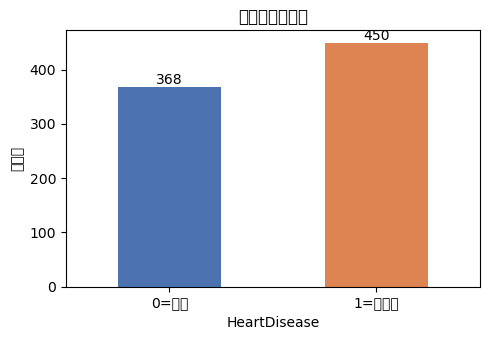

In [3]:
counts = train_df['HeartDisease'].value_counts().sort_index()
print(counts)
print('\n占比:')
print(train_df['HeartDisease'].value_counts(normalize=True).sort_index())

fig, ax = plt.subplots(figsize=(5, 3.5))
counts.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
ax.set_xticklabels(['0=正常', '1=心脏病'], rotation=0)
ax.set_ylabel('样本数')
ax.set_title('训练集类别分布')
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha='center')
plt.tight_layout()
plt.show()


In [4]:
print('=== 缺失值（NaN）===')
print(train_df.isnull().sum())
# 血压、胆固醇的0值是医学常识上不可能的，属于采集漏记
print('\n=== 异常零值（医学上不可能，视为缺失）===')
for col in ['RestingBP', 'Cholesterol']:
    n_zero = (train_df[col] == 0).sum()
    print(f'{col}: {n_zero} 条为 0 ({n_zero/len(train_df)*100:.1f}%)')


=== 缺失值（NaN）===
id                0
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

=== 异常零值（医学上不可能，视为缺失）===
RestingBP: 1 条为 0 (0.1%)
Cholesterol: 153 条为 0 (18.7%)


C:\Users\29797\AppData\Local\Temp\ipykernel_8996\2641086000.py:13: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\2641086000.py:13: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Anaconda\envs\DL\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Anaconda\envs\DL\Lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


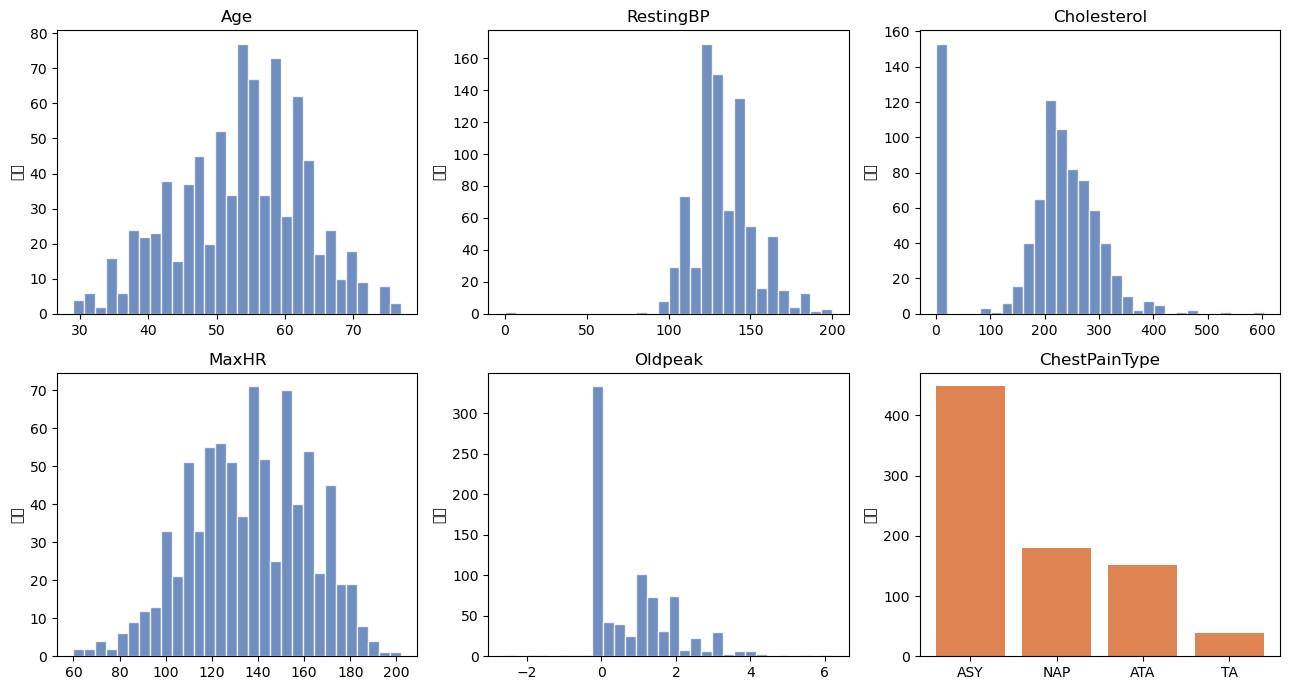

In [5]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(train_df[col], bins=30, color='#4C72B0', alpha=0.8, edgecolor='white')
    axes[i].set_title(col)
    axes[i].set_ylabel('频数')
axes[-1].bar(train_df['ChestPainType'].value_counts().index,
             train_df['ChestPainType'].value_counts().values,
             color='#DD8452')
axes[-1].set_title('ChestPainType')
axes[-1].set_ylabel('频数')
plt.tight_layout()
plt.show()


In [6]:
# 按特征类型分组
NUMERIC_COLS   = ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
BINARY_COLS    = ['Sex', 'ExerciseAngina']
MULTI_CAT_COLS = ['ChestPainType', 'RestingECG', 'ST_Slope']

# 第一步：异常0值统一替换成空值
for col in ['Cholesterol', 'RestingBP']:
    train_df.loc[train_df[col] == 0, col] = np.nan
    test_df.loc[test_df[col] == 0, col]   = np.nan

# 中位数填补空值（fit只在训练集做，测试集直接transform）
imputer = SimpleImputer(strategy='median')
train_num = imputer.fit_transform(train_df[NUMERIC_COLS])
test_num  = imputer.transform(test_df[NUMERIC_COLS])

# 数值标准化
scaler = StandardScaler()
train_num_scaled = scaler.fit_transform(train_num)
test_num_scaled  = scaler.transform(test_num)

# 二分类特征手动转0/1
sex_map    = {'M': 1, 'F': 0}
angina_map = {'Y': 1, 'N': 0}
def encode_binary(df):
    out = pd.DataFrame(index=df.index)
    out['Sex']            = df['Sex'].map(sex_map)
    out['ExerciseAngina'] = df['ExerciseAngina'].map(angina_map)
    return out
train_bin = encode_binary(train_df).values
test_bin  = encode_binary(test_df).values

# 多分类独热编码
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
train_multi = ohe.fit_transform(train_df[MULTI_CAT_COLS])
test_multi  = ohe.transform(test_df[MULTI_CAT_COLS])

# 拼最终特征矩阵，转32位浮点数
X_train_full = np.hstack([train_num_scaled, train_bin, train_multi]).astype(np.float32)
X_test       = np.hstack([test_num_scaled,  test_bin,  test_multi]).astype(np.float32)
y_train_full = train_df['HeartDisease'].values.astype(np.float32)
print(f'特征维度: {X_train_full.shape[1]}')
print(f'训练集总量: {X_train_full.shape[0]}, 测试集: {X_test.shape[0]}')


特征维度: 18
训练集总量: 818, 测试集: 100


In [7]:
# 切15%数据当验证集，分层抽样保证类别比例一致
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15,
    random_state=42,
    stratify=y_train_full
)
print(f'训练集: {X_train.shape[0]} 条, 验证集: {X_val.shape[0]} 条')

BATCH_SIZE = 32
# 打包成PyTorch数据集
train_ds = TensorDataset(torch.tensor(X_train), torch.tensor(y_train).unsqueeze(1))
val_ds   = TensorDataset(torch.tensor(X_val),   torch.tensor(y_val).unsqueeze(1))
# 做批量加载器：训练集打乱，验证集不打乱
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)

# 检查batch形状
for Xb, yb in train_loader:
    print(f'batch X shape: {Xb.shape}, y shape: {yb.shape}')
    break


训练集: 695 条, 验证集: 123 条
batch X shape: torch.Size([32, 18]), y shape: torch.Size([32, 1])


In [8]:
class HeartDiseaseClassifier(nn.Module):
    def __init__(self, input_size, hidden_sizes=(64, 32, 16), dropout=0.3):
        super(HeartDiseaseClassifier, self).__init__()
        layers = []
        prev_dim = input_size
        for h in hidden_sizes:
            layers.append(nn.Linear(prev_dim, h))   # 全连接层
            layers.append(nn.BatchNorm1d(h))         # 批归一化
            layers.append(nn.ReLU())                  # ReLU激活
            if dropout > 0:
                layers.append(nn.Dropout(dropout))   # Dropout防过拟合
            prev_dim = h
        layers.append(nn.Linear(prev_dim, 1))  # 输出层1个logit
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# 看模型结构和参数量
INPUT_DIM = X_train.shape[1]
model = HeartDiseaseClassifier(INPUT_DIM, hidden_sizes=(64, 32, 16), dropout=0.3)
model = model.to(device)
print(model)
print(f'\n可训练参数量: {sum(p.numel() for p in model.parameters() if p.requires_grad)}')


HeartDiseaseClassifier(
  (net): Sequential(
    (0): Linear(in_features=18, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.3, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.3, inplace=False)
    (12): Linear(in_features=16, out_features=1, bias=True)
  )
)

可训练参数量: 4065


In [9]:
def train(model, train_loader, val_loader, epochs, lr,
          weight_decay=1e-4, device='cuda', verbose=True):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=10, min_lr=1e-6
    )
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0
    best_state = None

    for epoch in range(epochs):
        # 训练阶段
        model.train()
        running_loss = 0.0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(Xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * Xb.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        # 验证阶段
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        with torch.no_grad():
            for Xb, yb in val_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                logits = model(Xb)
                loss = criterion(logits, yb)
                val_loss += loss.item() * Xb.size(0)
                preds = (torch.sigmoid(logits) >= 0.5).float()
                correct += (preds == yb).sum().item()
                total += yb.size(0)
        val_loss /= len(val_loader.dataset)
        val_acc = correct / total
        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        if verbose and ((epoch + 1) % 10 == 0 or epoch == 0):
            print(f'Epoch {epoch+1:3d}/{epochs} | '
                  f'train_loss {train_loss:.4f} | val_loss {val_loss:.4f} | '
                  f'val_acc {val_acc:.4f} | lr {optimizer.param_groups[0]["lr"]:.2e}')

    if best_state is not None:
        model.load_state_dict(best_state)
    if verbose:
        print(f'\n训练完成，最佳验证集准确率: {best_val_acc:.4f}')
    return model, history


Epoch   1/150 | train_loss 0.6668 | val_loss 0.6273 | val_acc 0.7724 | lr 1.00e-03
Epoch  10/150 | train_loss 0.3932 | val_loss 0.3936 | val_acc 0.8130 | lr 1.00e-03
Epoch  20/150 | train_loss 0.3122 | val_loss 0.4134 | val_acc 0.8211 | lr 1.00e-03
Epoch  30/150 | train_loss 0.2897 | val_loss 0.3916 | val_acc 0.8374 | lr 5.00e-04
Epoch  40/150 | train_loss 0.2961 | val_loss 0.3993 | val_acc 0.8374 | lr 2.50e-04
Epoch  50/150 | train_loss 0.3070 | val_loss 0.4029 | val_acc 0.8293 | lr 1.25e-04
Epoch  60/150 | train_loss 0.2989 | val_loss 0.4100 | val_acc 0.8293 | lr 6.25e-05
Epoch  70/150 | train_loss 0.2848 | val_loss 0.4023 | val_acc 0.8374 | lr 6.25e-05
Epoch  80/150 | train_loss 0.3138 | val_loss 0.4045 | val_acc 0.8374 | lr 3.13e-05
Epoch  90/150 | train_loss 0.3048 | val_loss 0.4139 | val_acc 0.8293 | lr 1.56e-05
Epoch 100/150 | train_loss 0.2730 | val_loss 0.4095 | val_acc 0.8293 | lr 7.81e-06
Epoch 110/150 | train_loss 0.2994 | val_loss 0.4176 | val_acc 0.8211 | lr 3.91e-06
Epoc

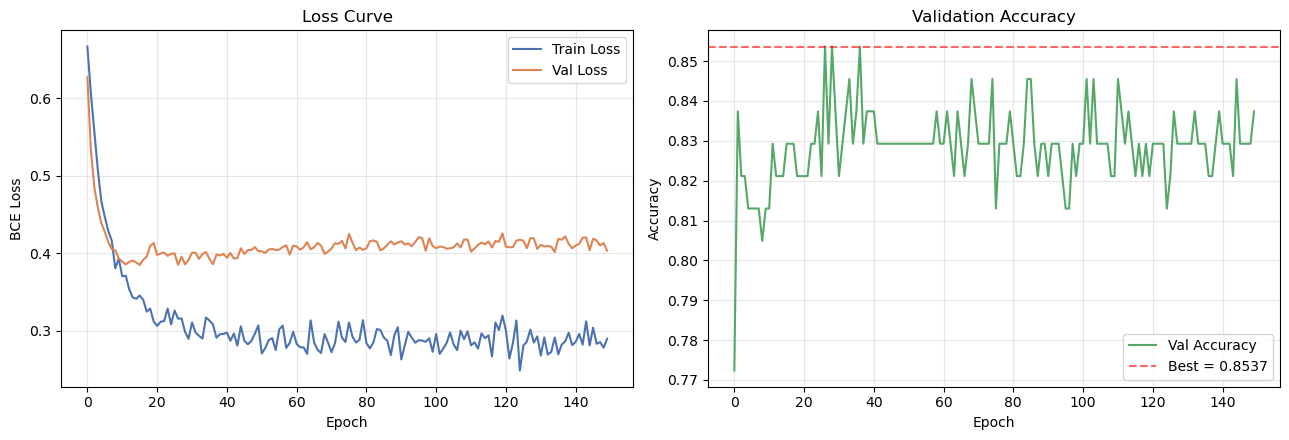

In [10]:
set_seed(42)
model = HeartDiseaseClassifier(INPUT_DIM, hidden_sizes=(64, 32, 16), dropout=0.3)
model, history = train(
    model, train_loader, val_loader,
    epochs=150, lr=1e-3, weight_decay=1e-4, device=device
)

# 画loss和准确率曲线
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(history['train_loss'], label='Train Loss', color='#4C72B0')
axes[0].plot(history['val_loss'],   label='Val Loss',   color='#DD8452')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('BCE Loss')
axes[0].set_title('Loss Curve')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history['val_acc'], label='Val Accuracy', color='#55A868')
axes[1].axhline(y=max(history['val_acc']), color='r', linestyle='--', alpha=0.6,
                label=f'Best = {max(history["val_acc"]):.4f}')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3494354797.py:28: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3494354797.py:28: UserWarning: Glyph 24120 (\N{CJK UNIFIED IDEOGRAPH-5E38}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3494354797.py:28: UserWarning: Glyph 24515 (\N{CJK UNIFIED IDEOGRAPH-5FC3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3494354797.py:28: UserWarning: Glyph 33039 (\N{CJK UNIFIED IDEOGRAPH-810F}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3494354797.py:28: UserWarning: Glyph 30149 (\N{CJK UNIFIED IDEOGRAPH-75C5}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\3494354797.py:28: UserWarning: Glyph 39044 (\N{CJK 

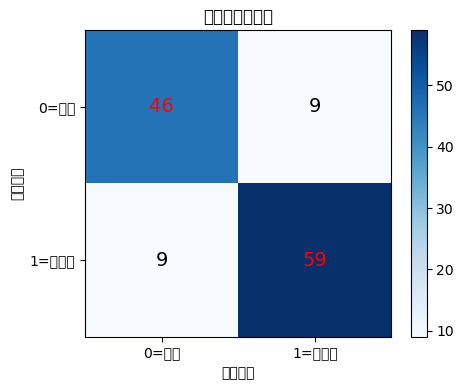

验证集分类报告:
              precision    recall  f1-score   support

        0=正常     0.8364    0.8364    0.8364        55
       1=心脏病     0.8676    0.8676    0.8676        68

    accuracy                         0.8537       123
   macro avg     0.8520    0.8520    0.8520       123
weighted avg     0.8537    0.8537    0.8537       123

验证集准确率: 0.8537


In [11]:
def evaluate(model, data_loader, device='cuda'):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for Xb, yb in data_loader:
            Xb = Xb.to(device)
            logits = model(Xb)
            preds = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
            all_preds.extend(preds.flatten())
            all_labels.extend(yb.numpy().flatten())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = evaluate(model, val_loader, device=device)
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap='Blues')
plt.colorbar(im, ax=ax)
ax.set_xticks([0, 1]); ax.set_xticklabels(['0=正常', '1=心脏病'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['0=正常', '1=心脏病'])
ax.set_xlabel('预测标签')
ax.set_ylabel('真实标签')
ax.set_title('验证集混淆矩阵')
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                color='red' if cm[i, j] > cm.max() / 2 else 'black', fontsize=14)
plt.tight_layout()
plt.show()

print('验证集分类报告:')
print(classification_report(y_true, y_pred, target_names=['0=正常', '1=心脏病'], digits=4))
print(f'验证集准确率: {accuracy_score(y_true, y_pred):.4f}')


In [12]:
test_ds = TensorDataset(torch.tensor(X_test))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
model.eval()
test_preds = []
with torch.no_grad():
    for (Xb,) in test_loader:
        Xb = Xb.to(device)
        logits = model(Xb)
        preds = (torch.sigmoid(logits) >= 0.5).int().cpu().numpy()
        test_preds.extend(preds.flatten())

submission = pd.DataFrame({
    'id': test_df['id'],
    'HeartDisease': np.array(test_preds, dtype=int)
})
submission.to_csv('submission.csv', index=False)
print('提交文件前 5 行:')
print(submission.head())
print(f'\n预测正类（心脏病）数量: {submission["HeartDisease"].sum()} / {len(submission)}')
print(f'已保存: {os.path.abspath("submission.csv")}')


提交文件前 5 行:
    id  HeartDisease
0  669             0
1   31             1
2  378             1
3  536             1
4  808             0

预测正类（心脏病）数量: 63 / 100
已保存: C:\Users\29797\PycharmProjects\PythonProject\ml-3\submission.csv


No Dropout (dropout=0)    | best_val_acc 0.8537 | train_loss 0.0983 | val_loss 0.6883
Default (dropout=0.3)     | best_val_acc 0.8537 | train_loss 0.2730 | val_loss 0.4095
Wider [128,64] + dropout  | best_val_acc 0.8455 | train_loss 0.2395 | val_loss 0.4612

=== 实验对比汇总 ===
                  config  best_val_acc  final_train_loss  final_val_loss
  No Dropout (dropout=0)      0.853659          0.098272        0.688329
   Default (dropout=0.3)      0.853659          0.272970        0.409492
Wider [128,64] + dropout      0.845528          0.239497        0.461157


C:\Users\29797\AppData\Local\Temp\ipykernel_8996\1589234500.py:39: UserWarning: Glyph 19981 (\N{CJK UNIFIED IDEOGRAPH-4E0D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\1589234500.py:39: UserWarning: Glyph 21516 (\N{CJK UNIFIED IDEOGRAPH-540C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\1589234500.py:39: UserWarning: Glyph 37197 (\N{CJK UNIFIED IDEOGRAPH-914D}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\1589234500.py:39: UserWarning: Glyph 32622 (\N{CJK UNIFIED IDEOGRAPH-7F6E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\1589234500.py:39: UserWarning: Glyph 30340 (\N{CJK UNIFIED IDEOGRAPH-7684}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\29797\AppData\Local\Temp\ipykernel_8996\1589234500.py:39: UserWarning: Glyph 26368 (\N{CJK 

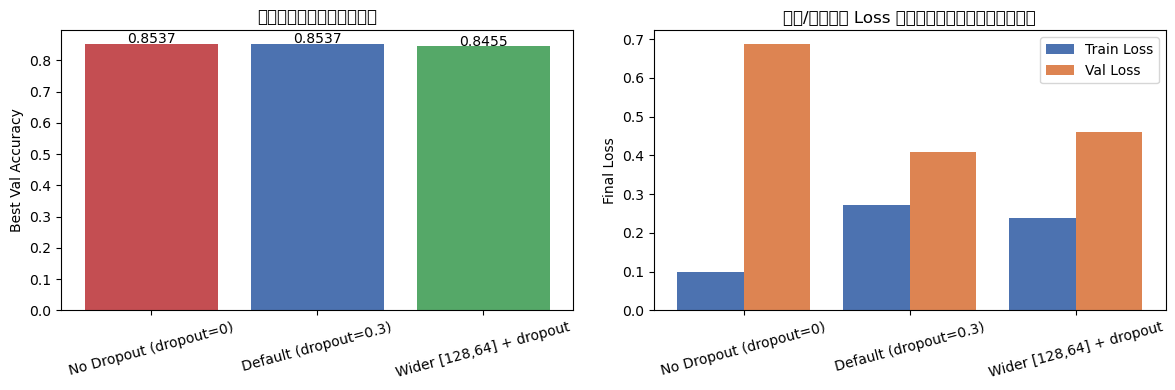

In [13]:
def run_experiment(name, hidden_sizes, dropout, epochs=100):
    set_seed(42)
    m = HeartDiseaseClassifier(INPUT_DIM, hidden_sizes=hidden_sizes, dropout=dropout)
    m, h = train(m, train_loader, val_loader,
                  epochs=epochs, lr=1e-3, weight_decay=1e-4,
                  device=device, verbose=False)
    best_acc = max(h['val_acc'])
    final_train_loss = h['train_loss'][-1]
    final_val_loss = h['val_loss'][-1]
    print(f'{name:25s} | best_val_acc {best_acc:.4f} | '
          f'train_loss {final_train_loss:.4f} | val_loss {final_val_loss:.4f}')
    return {'config': name, 'best_val_acc': best_acc,
            'final_train_loss': final_train_loss, 'final_val_loss': final_val_loss}

results = []
results.append(run_experiment('No Dropout (dropout=0)',   (64, 32, 16), 0.0))
results.append(run_experiment('Default (dropout=0.3)',     (64, 32, 16), 0.3))
results.append(run_experiment('Wider [128,64] + dropout', (128, 64),     0.3))

exp_df = pd.DataFrame(results)
print('\n=== 实验对比汇总 ===')
print(exp_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(exp_df['config'], exp_df['best_val_acc'], color=['#C44E52', '#4C72B0', '#55A868'])
axes[0].set_ylabel('Best Val Accuracy')
axes[0].set_title('不同配置的最佳验证准确率')
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(exp_df['best_val_acc']):
    axes[0].text(i, v + 0.002, f'{v:.4f}', ha='center')

axes[1].bar(np.arange(len(exp_df)) - 0.2, exp_df['final_train_loss'], 0.4, label='Train Loss', color='#4C72B0')
axes[1].bar(np.arange(len(exp_df)) + 0.2, exp_df['final_val_loss'],   0.4, label='Val Loss',   color='#DD8452')
axes[1].set_xticks(range(len(exp_df)))
axes[1].set_xticklabels(exp_df['config'], rotation=15)
axes[1].set_ylabel('Final Loss')
axes[1].set_title('训练/验证最终 Loss 对比（差距越大过拟合越严重）')
axes[1].legend()
plt.tight_layout()
plt.show()
